# CS 577 Homework 3 Attention and Transformer Forward

**Student starter notebook**

Due November 8, 2026, 11:59 p.m. Central Time. Individual work; 8% of the
course grade. Read the assignment PDF before starting. Complete the eight
TODO functions in `hw3_attention.py` and the notebook TODOs below.
Before completion, NotImplementedError failures are expected. Before
submission, restart the kernel and run ALL cells with visible outputs on CPU.
Keep written calculations and interpretations in your LaTeX/PDF report.


In [1]:
import copy
import platform
import subprocess
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import hw3_attention as h

np.set_printoptions(precision=6, suppress=True)
torch.manual_seed(577)
torch.set_num_threads(1)
print({"Python": platform.python_version(), "NumPy": np.__version__,
       "PyTorch": torch.__version__, "Matplotlib": matplotlib.__version__,
       "device": "cpu", "seed": 577})

def max_error(a, b):
    return float(np.max(np.abs(np.asarray(a) - np.asarray(b))))


{'Python': '3.11.18', 'NumPy': '2.4.6', 'PyTorch': '2.15.0', 'Matplotlib': '3.11.2', 'device': 'cpu', 'seed': 577}


## 0 Setup and axis conventions

Put your axis meanings and the `(B,1,1,Tk)` mask explanation in the report.
This cell calls the public tests; run it after implementing the module.


In [2]:
result = subprocess.run([sys.executable, "-m", "unittest", "-v", "test_hw3_public.py"],
                        capture_output=True, text=True)
print(result.stdout)
print(result.stderr)
print("public-test return code:", result.returncode)
assert result.returncode == 0, "Complete/correct your functions before the final run-all."



test_01_stable_softmax_and_mask (test_hw3_public.AttentionTests.test_01_stable_softmax_and_mask) ... ok
test_02_softmax_last_axis_and_key_mask_broadcast (test_hw3_public.AttentionTests.test_02_softmax_last_axis_and_key_mask_broadcast) ... ok
test_03_causal_mask_includes_self (test_hw3_public.AttentionTests.test_03_causal_mask_includes_self) ... ok
test_04_attention_uniform_reads_and_rectangular_shapes (test_hw3_public.AttentionTests.test_04_attention_uniform_reads_and_rectangular_shapes) ... ok
test_05_hand_case_causal_visibility (test_hw3_public.AttentionTests.test_05_hand_case_causal_visibility) ... ok
test_06_head_axes_and_exact_roundtrip (test_hw3_public.HeadAndBlockTests.test_06_head_axes_and_exact_roundtrip) ... ok
test_07_mha_cache_and_identity_uniform_case (test_hw3_public.HeadAndBlockTests.test_07_mha_cache_and_identity_uniform_case) ... ok
test_08_mha_cross_attention_and_mask (test_hw3_public.HeadAndBlockTests.test_08_mha_cross_attention_and_mask) ... ok
test_09_position_vec

## 1 and 2 One attention calculation

Rows are The, cat, sleeps. First complete your hand calculation in the
written report, then use this cell to check full-precision values. The
returned score cache is scaled BEFORE masking; weights reflect the mask.


In [3]:
Q, K, V = h.hand_case()
Y_full, c_full = h.scaled_dot_product_attention(Q, K, V)
Y_causal, c_causal = h.scaled_dot_product_attention(Q, K, V, h.causal_mask(3))
print("QK transpose:\n", (Q @ K.swapaxes(-1, -2))[0, 0])
print("scaled scores:\n", c_full["scores"][0, 0])
print("full weights:\n", c_full["weights"][0, 0])
print("full outputs:\n", Y_full[0, 0])
print("causal allowed:\n", h.causal_mask(3))
print("causal weights:\n", c_causal["weights"][0, 0])
print("causal outputs:\n", Y_causal[0, 0])


QK transpose:
 [[1. 0. 1.]
 [0. 1. 1.]
 [1. 1. 2.]]
scaled scores:
 [[0.707107 0.       0.707107]
 [0.       0.707107 0.707107]
 [0.707107 0.707107 1.414214]]
full weights:
 [[0.401112 0.197776 0.401112]
 [0.197776 0.401112 0.401112]
 [0.248255 0.248255 0.50349 ]]
full outputs:
 [[1.604448 0.796664]
 [1.401112 1.203336]
 [1.758725 1.      ]]
causal allowed:
 [[ True False False]
 [ True  True False]
 [ True  True  True]]
causal weights:
 [[1.       0.       0.      ]
 [0.330238 0.669762 0.      ]
 [0.248255 0.248255 0.50349 ]]
causal outputs:
 [[1.       0.      ]
 [0.330238 1.339523]
 [1.758725 1.      ]]


## 2.1 Stability and a fully blocked row

This contract defines a zero-row guard when no key is allowed. It is not
ordinary softmax on all negative infinity. Explain your implementation
and its numerical behavior in the report.


In [4]:
scores_extreme = np.array([[1000., 999., -1000.], [1., 2., 3.]])
allowed_extreme = np.array([[True, True, False], [False, False, False]])
with np.errstate(over="raise", invalid="raise", divide="raise"):
    probabilities = h.masked_softmax(scores_extreme, allowed_extreme)
print("guarded weights:\n", probabilities)
print("row sums:", probabilities.sum(-1), "finite:", np.isfinite(probabilities).all())


guarded weights:
 [[0.731059 0.268941 0.      ]
 [0.       0.       0.      ]]
row sums: [1. 0.] finite: True


## 2.3 Padding and causal visibility

Two examples share storage length four. Actual lengths are two and four.
Implement the mask construction below. Padded query outputs are not used;
this check compares only valid queries. Print both combined masks and the
largest forbidden probability. The returned mask must be Boolean.


In [5]:
rng = np.random.default_rng(577)
Q_pad = rng.normal(size=(2, 2, 4, 2))
K_pad = rng.normal(size=(2, 2, 4, 2))
V_pad = rng.normal(size=(2, 2, 4, 3))
lengths = np.array([2, 4])


In [6]:
# TODO: build key_valid:(B,T), key_allowed:(B,1,1,T),
# and combined_allowed:(B,1,T,T) with causal visibility.
if Q_pad is None or K_pad is None or V_pad is None or lengths is None:
    raise ValueError("Missing required inputs for padding and causal mask construction")
if Q_pad.ndim != 4 or K_pad.ndim != 4 or V_pad.ndim != 4:
    raise ValueError("Q_pad, K_pad, and V_pad must be 4-dimensional arrays")
if lengths.ndim != 1:
    raise ValueError("lengths must be a 1-dimensional array")
if Q_pad.shape[3] != K_pad.shape[3]:
     raise ValueError("The feature dimension of Q_pad and K_pad must match")

# Build key_valid, key_allowed, and combined_allowed
B, H, T, dk = Q_pad.shape
key_valid = np.arange(T)[None, :] < lengths[:, None]  # (B,T)
key_allowed = key_valid[:, None, None, :]  # (B,1,1,T)
causal = h.causal_mask(T)[None, None]
combined_allowed = key_allowed & causal        # (B, 1, T, T)
assert key_valid.shape == (B, T)
assert key_allowed.shape == (B, 1, 1, T)
assert combined_allowed.shape == (B, 1, T, T)
print("Padding and causal mask construction completed successfully.")


Padding and causal mask construction completed successfully.


In [7]:
padded_output, padded_cache = h.scaled_dot_product_attention(
    Q_pad, K_pad, V_pad, combined_allowed)
altered_values = V_pad.copy()
altered_values[0, :, 2:, :] *= 1e6
changed_output, _ = h.scaled_dot_product_attention(
    Q_pad, K_pad, altered_values, combined_allowed)
visible = np.broadcast_to(combined_allowed, padded_cache["weights"].shape)
forbidden_max = float(np.max(padded_cache["weights"][~visible]))
errors = [max_error(padded_output[b, :, :n], changed_output[b, :, :n])
          for b, n in enumerate(lengths)]
print("combined masks:\n", combined_allowed[:, 0].astype(int))
print("largest forbidden weight:", forbidden_max)
print("valid-query changes after padding perturbation:", errors)
assert forbidden_max == 0 and max(errors) < 1e-9


combined masks:
 [[[1 0 0 0]
  [1 1 0 0]
  [1 1 0 0]
  [1 1 0 0]]

 [[1 0 0 0]
  [1 1 0 0]
  [1 1 1 0]
  [1 1 1 1]]]
largest forbidden weight: 0.0
valid-query changes after padding perturbation: [0.0, 0.0]


## 3.1 Multiple heads on the same token embeddings

The parameter helper supplies four dense, full-width projections. They
are sample random parameters, not trained language representations.
Report the shapes, weights and outputs, then interpret the maps.


input: (1, 3, 4)
projected full width: (1, 3, 4)
cache shapes: {'Q': (1, 2, 3, 2), 'K': (1, 2, 3, 2), 'V': (1, 2, 3, 2), 'scores': (1, 2, 3, 3), 'weights': (1, 2, 3, 3), 'head_outputs': (1, 2, 3, 2), 'merged': (1, 3, 4)}
head 0 weights:
 [[0.333564 0.305695 0.360742]
 [0.294529 0.382591 0.32288 ]
 [0.330969 0.31465  0.35438 ]]
head 1 weights:
 [[0.343257 0.336953 0.31979 ]
 [0.288356 0.313887 0.397757]
 [0.329307 0.334592 0.336101]]
final MHA output:
 [[-0.802509  0.297039 -0.294996  0.286971]
 [-0.727542  0.405107 -0.232164  0.297766]
 [-0.793182  0.309142 -0.288717  0.285779]]


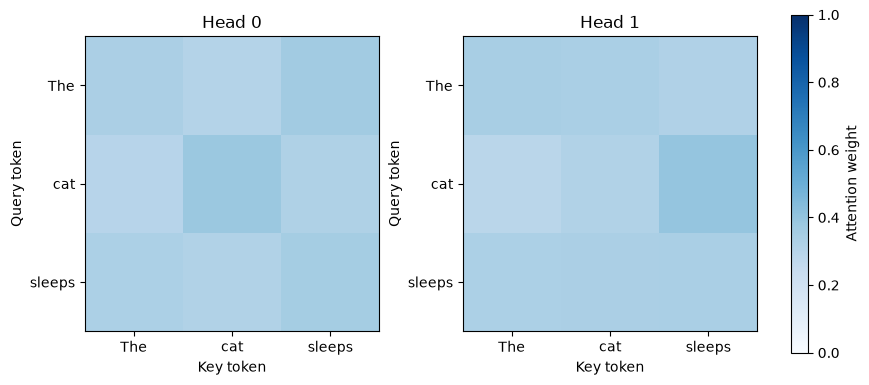

In [8]:
X = h.token_case()
mha_params = h.initialize_mha(4, seed=577)
Y_two, c_two = h.multi_head_attention(X, None, mha_params, 2)
print("input:", X.shape)
print("projected full width:", (X @ mha_params["Wq"]).shape)
print("cache shapes:", {key: value.shape for key, value in c_two.items()})
print("head 0 weights:\n", c_two["weights"][0, 0])
print("head 1 weights:\n", c_two["weights"][0, 1])
print("final MHA output:\n", Y_two[0])

fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.8), constrained_layout=True)
words = ["The", "cat", "sleeps"]
for head, ax in enumerate(axes):
    im = ax.imshow(c_two["weights"][0, head], vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(3), words)
    ax.set_yticks(range(3), words)
    ax.set_xlabel("Key token"); ax.set_ylabel("Query token")
    ax.set_title(f"Head {head}")
fig.colorbar(im, ax=axes, label="Attention weight")
fig.savefig("hw3_attention_maps.png", dpi=180)
plt.show()


## 3.2 Independent PyTorch reference

Complete the function below using nn.MultiheadAttention. Map parameters
exactly as stated in the PDF: transpose each NumPy matrix, concatenate
Q/K/V input weights vertically, and transpose the output projection.
Use CPU float64, no biases/dropout, batch_first=True, and request per-head
weights. For this function allowed is None or a 2D (Tq,Tk) mask.
nn.MultiheadAttention uses True=blocked, so invert an allowed mask.


In [9]:
def torch_mha_reference(X_query, X_context, params, num_heads, allowed=None):
    # TODO: return (NumPy output, NumPy per-head weights) from a faithful
    # independent torch.nn.MultiheadAttention module.

    if X_context is None:
        X_context = X_query

    B, Tq, D = X_query.shape
    Tk = X_context.shape[1]

    query_t = torch.as_tensor(X_query, dtype=torch.float64)
    context_t = torch.as_tensor(X_context, dtype=torch.float64)

    mha = torch.nn.MultiheadAttention(
        embed_dim=D,
        num_heads=num_heads,
        batch_first=True,
        bias=False,
        dropout=0.0,  # Added explicitly
        dtype=torch.float64,
        device="cpu"
    )

    with torch.no_grad():
        Wq_T = torch.as_tensor(params["Wq"].T, dtype=torch.float64)
        Wk_T = torch.as_tensor(params["Wk"].T, dtype=torch.float64)
        Wv_T = torch.as_tensor(params["Wv"].T, dtype=torch.float64)
        Wo_T = torch.as_tensor(params["Wo"].T, dtype=torch.float64)

        mha.in_proj_weight.copy_(
            torch.cat([Wq_T, Wk_T, Wv_T], dim=0)
        )
        mha.out_proj.weight.copy_(Wo_T)

    attn_mask = None

    if allowed is not None:
        allowed = np.broadcast_to(allowed, (B, num_heads, Tq, Tk))
        allowed = ~allowed
        allowed = allowed.reshape(B * num_heads, Tq, Tk)
        attn_mask = torch.as_tensor(allowed, dtype=torch.bool)

    mha.eval()

    with torch.no_grad():
        torch_output, torch_per_head_weights = mha(
            query_t,
            context_t,
            context_t,
            attn_mask=attn_mask,
            need_weights=True,
            average_attn_weights=False
        )

    return (
       torch_output.detach().numpy(),
       torch_per_head_weights.detach().numpy()
   )

In [10]:
reference_checks = []
for name, query, context, allowed in [
    ("unmasked self", X, None, None),
    ("causal self", X, None, h.causal_mask(3)),
    ("rectangular cross", X[:, :2], X, None),
]:
    ours, cached = h.multi_head_attention(query, context, mha_params, 2, allowed)
    reference, reference_weights = torch_mha_reference(
        query, context, mha_params, 2, allowed)
    errors = (max_error(ours, reference), max_error(cached["weights"], reference_weights))
    reference_checks.append((name, *errors))
print("case | maximum output error | maximum per-head weight error")
for row in reference_checks:
    print(row)
assert max(max(row[1:]) for row in reference_checks) < 1e-9


case | maximum output error | maximum per-head weight error
('unmasked self', 1.1102230246251565e-16, 5.551115123125783e-17)
('causal self', 1.1102230246251565e-16, 5.551115123125783e-17)
('rectangular cross', 1.1102230246251565e-16, 5.551115123125783e-17)


## 3.3 Head count and removing one head output

Compare fixed total width and fixed projections at H=1 and H=2. Then
independently remove each head output BEFORE the output projection.
This is an ablation of output features, not a modification of token masks.
Interpret the actual changes; do not claim a semantic function from
untrained maps or improved accuracy from this forward-only experiment.


In [11]:
Y_one, c_one = h.multi_head_attention(X, None, mha_params, 1)
count = sum(p.size for p in mha_params.values())
print("H=1: features/head", c_one["Q"].shape[-1], "scores", c_one["scores"].shape,
      "parameters", count)
print("H=2: features/head", c_two["Q"].shape[-1], "scores", c_two["scores"].shape,
      "parameters", count)
print("maximum H=1 vs H=2 output difference:", max_error(Y_one, Y_two))


H=1: features/head 4 scores (1, 1, 3, 3) parameters 64
H=2: features/head 2 scores (1, 2, 3, 3) parameters 64
maximum H=1 vs H=2 output difference: 0.03971706792468749


In [12]:
# TODO: remove each head output separately and report the two maximum
# output changes after merging and applying Wo. Work on copies.
head_changes = []

num_heads = c_two["head_outputs"].shape[1]

for j in range(num_heads):

    ablated = c_two["head_outputs"].copy()
    ablated[:, j, :] = 0
    merged = h.merge_heads(ablated)
    output = merged @ mha_params["Wo"]
    max_diff = np.max(np.abs(output - Y_two))
    head_changes.append(max_diff)

print("sanity check (no ablation):",
      max_error(h.merge_heads(c_two["head_outputs"]) @ mha_params["Wo"], Y_two))
for j, change in enumerate(head_changes):
    print(f"remove head {j}: max output change = {change:.6f}")

sanity check (no ablation): 0.0
remove head 0: max output change = 0.454920
remove head 1: max output change = 0.466943


## 4.1 One pre-norm Transformer block

Use the specified pre-norm/ReLU order with provided LayerNorm.
Independently reproduce the same block in PyTorch below; keep normalization
axis, epsilon, parameters, residual paths and mask exactly matched.


In [13]:
block_params = h.initialize_block(4, 8, seed=577)
Z, block_cache = h.transformer_block(X, block_params, 2)
print("block cache shapes:", {key: value.shape for key, value in block_cache.items()})
print("block output:\n", Z[0])


block cache shapes: {'N1': (1, 3, 4), 'U': (1, 3, 4), 'N2': (1, 3, 4), 'F': (1, 3, 4), 'Z': (1, 3, 4), 'weights': (1, 2, 3, 3)}
block output:
 [[ 1.698821 -1.129889  0.4089    0.921563]
 [ 0.905609  0.742011  1.573256 -1.155096]
 [ 0.654205  0.955565 -0.176761 -0.079603]]


In [14]:
def torch_block_reference(X, params, num_heads, allowed=None):
    # TODO: recreate the SAME pre-norm/ReLU block with PyTorch operations
    # and your independent torch_mha_reference. Return a NumPy array.

    X_t = torch.as_tensor(X, dtype=torch.float64)

    ln1_gamma = torch.as_tensor(params["ln1_gamma"], dtype=torch.float64)
    ln1_beta = torch.as_tensor(params["ln1_beta"], dtype=torch.float64)
    ln2_gamma = torch.as_tensor(params["ln2_gamma"], dtype=torch.float64)
    ln2_beta = torch.as_tensor(params["ln2_beta"], dtype=torch.float64) 

    N1 = F.layer_norm(
        X_t,
        normalized_shape=(X_t.shape[-1],),
        weight=ln1_gamma,
        bias=ln1_beta,
        eps=1e-5
    )

    attention_output_np, _ = torch_mha_reference(
    N1.detach().numpy(), None, params["mha"], num_heads, allowed
    )    
    attention_output = torch.as_tensor( attention_output_np, dtype=torch.float64) 

    U = X_t + attention_output

    N2 = F.layer_norm(
        U,
        normalized_shape=(U.shape[-1],),
        weight=ln2_gamma,
        bias=ln2_beta,
        eps=1e-5
    )

    W1 = torch.as_tensor(params["W1"], dtype=torch.float64)
    b1 = torch.as_tensor(params["b1"], dtype=torch.float64)
    W2 = torch.as_tensor(params["W2"], dtype=torch.float64)
    b2 = torch.as_tensor(params["b2"], dtype=torch.float64)

    FFN_output = torch.relu(N2 @ W1 + b1) @ W2 + b2

    Z = U + FFN_output

    return Z.detach().numpy()

In [15]:
Z_reference = torch_block_reference(X, block_params, 2)
print("NumPy vs PyTorch block max error:", max_error(Z, Z_reference))
assert max_error(Z, Z_reference) < 1e-9
zero_updates = copy.deepcopy(block_params)
zero_updates["mha"]["Wo"][:] = 0.
zero_updates["W2"][:] = 0.
zero_updates["b2"][:] = 0.
Z_zero, _ = h.transformer_block(X, zero_updates, 2)
print("zero-update residual max error:", max_error(Z_zero, X))
assert max_error(Z_zero, X) < 1e-9


NumPy vs PyTorch block max error: 6.661338147750939e-16
zero-update residual max error: 0.0


## 4.2 Position vectors and reordered tokens

PE is added feature by feature, retaining shape (B,T,D). In the second
comparison, token embeddings move but position vectors stay in their slots.
Use no causal mask in this experiment. Explain the TWO reported errors.


In [16]:
PE = h.sinusoidal_positions(3, 4)
order = np.array([2, 0, 1])
X_position = X + PE[None]
Z_reordered, _ = h.transformer_block(X[:, order], block_params, 2)
no_position_error = max_error(Z_reordered, Z[:, order])
Z_position, _ = h.transformer_block(X_position, block_params, 2)
Z_reordered_position, _ = h.transformer_block(X[:, order] + PE[None], block_params, 2)
position_error = max_error(Z_reordered_position, Z_position[:, order])
print("position vectors:\n", PE)
print("input plus positions:\n", X_position[0])
print("reordering error without positions:", no_position_error)
print("reordering error with positions attached to slots:", position_error)
assert no_position_error < 1e-9


position vectors:
 [[ 0.        1.        0.        1.      ]
 [ 0.841471  0.540302  0.01      0.99995 ]
 [ 0.909297 -0.416147  0.019999  0.9998  ]]
input plus positions:
 [[1.       1.       0.       2.      ]
 [0.841471 1.540302 1.01     0.99995 ]
 [1.909297 0.583853 0.019999 0.9998  ]]
reordering error without positions: 5.551115123125783e-16
reordering error with positions attached to slots: 1.2615816137977496


## 4.3 Change only the last input

Both runs use the same fixed position vectors. Compare the first TWO
output positions, first with causal attention and then with all keys visible.
Explain how the allowed attention paths account for the measured change.


In [17]:
X_changed = X_position.copy()
X_changed[:, 2] += np.array([5., -3., 2., -4.])
prefix_errors = {}
for name, allowed in [("causal", h.causal_mask(3)), ("unmasked", None)]:
    original, _ = h.transformer_block(X_position, block_params, 2, allowed)
    altered, _ = h.transformer_block(X_changed, block_params, 2, allowed)
    prefix_errors[name] = max_error(original[:, :2], altered[:, :2])
print("first-two-position maximum errors:", prefix_errors)
assert prefix_errors["causal"] < 1e-9


first-two-position maximum errors: {'causal': 0.0, 'unmasked': 0.5172628190448587}


## 5 Written architecture comparison and disclosure

In the report, trace BOS -> Le and Le -> chat in encoder-decoder generation.
Define the vectors used for queries and source keys/values. Then trace the
final prompt position in decoder-only generation and explain per-query
causal visibility during prefill. BOS is supplied in the stated example.

Include your hand calculation, measured-error tables, labeled attention
maps, head comparisons, position/causal interpretations, and assistance/AI
disclosure. The report should be understandable without guessing new symbols.
